# PatchCore bottle QC: results report

This notebook reads only `results/` and `docs/`. The first cell blocks every other path inside the project except the installed libraries in `.venv/`, so it cannot open `data/`, `splits/` or any test image. Every number here comes from files written by `src/eval.py` (single test run, 2026-10-26) and the earlier val-only scripts.

In [1]:
import builtins, io, json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.stats import beta

ROOT = Path.cwd().resolve()
R, D = ROOT / "results", ROOT / "docs"
ALLOWED = (R, D, ROOT / ".venv")   # .venv: installed libraries (fonts, configs), not project data
_open = builtins.open


def guarded_open(file, *args, **kwargs):
    """Refuse any path inside the project that is not under results/, docs/ or the library folder .venv/."""
    if isinstance(file, (str, Path)):
        p = Path(file).resolve()
        if p.is_relative_to(ROOT) and not any(p.is_relative_to(a) for a in ALLOWED):
            raise PermissionError(f"report.ipynb reads only results/ and docs/: {p.relative_to(ROOT)}")
    return _open(file, *args, **kwargs)


builtins.open = io.open = guarded_open
open = guarded_open   # IPython puts its own open() in the notebook namespace; route it through the guard too
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)
try:   # the probe path does not exist, so even a broken guard could not open a real file
    open(ROOT / "data" / "guard_probe_does_not_exist.png", "rb")
    raise AssertionError("guard did not fire")
except PermissionError as e:
    print("guard OK:", e)

guard OK: report.ipynb reads only results/ and docs/: data\guard_probe_does_not_exist.png


## 1. Data and curation
From `docs/curation_log.md`.

In [2]:
log = (D / "curation_log.md").read_text(encoding="utf-8")
curation, architecture = log.split("## Architecture")
display(Markdown(curation))

# Curation log: MVTec AD bottle

Produced by `python -m src.data` (seed 42). Splits are in `splits/`. `splits/manifest.json` pins the SHA-256 of each split CSV.

## Source and license
- Dataset: MVTec AD, category `bottle` (Bergmann et al., "MVTec AD: A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection", CVPR 2019).
- Obtained from a third-party mirror, https://huggingface.co/datasets/aristrops/mvtec-concepts (bottle train, test, ground_truth only). Stored read-only at `data/mvtec/bottle`, not committed to git.
- License: CC BY-NC-SA 4.0, so non-commercial use only. This project is coursework. A commercial MedVision deployment would need the manufacturer's own images under its own terms.

## Why bottle
The bottle is a rigid part photographed top-down from a fixed viewpoint against a fixed background. Of the MVTec categories, it is the closest stand-in for a molded medical-device component on an inspection line. Its defect types (large breaks, small chips on the rim, contamination inside) are the kinds of failures a molded part shows.

## Integrity checks (every run of data.py)
- Folder names and counts must match MVTec AD bottle exactly: train/good 209; test good 20, broken_large 20, broken_small 22, contamination 21.
- Every image must be 900x900, the size of the original release. This check is there because the data came from a mirror, and matching counts alone do not prove these are the original files. It cannot prove the files are byte-identical to MVTec's release, because we have no official per-file checksums. The SHA-256 column in each CSV pins exactly which files we used.
- Every image is hashed with SHA-256. A re-run re-hashes every file and checks it against the CSVs, checks each CSV against the manifest, and stops on any mismatch. A tampered `val.csv` was caught this way during testing.
- `--force` rebuilds byte-identical CSVs (verified: all four manifest hashes unchanged).

## Exact duplicates
Duplicates were checked by SHA-256 within each split and across splits.

| check | count |
|---|---|
| within fit / val / calib / test | 0 / 0 / 0 / 0 |
| fit x val, fit x test, val x test | 0, 0, 0 |
| calib not in fit, calib x val, calib x test | 0, 0, 0 |

## Splits
| split | source | images | good | defect | used for |
|---|---|---|---|---|---|
| fit | train/good minus val | 188 | 188 | 0 | memory bank (coreset) |
| val | 10% of train/good, seed 42 | 21 | 21 | 0 | thresholds (with synthetic defects made from val only), attack smoke tests |
| calib | 50 drawn from fit, seed 42 | 50 | 50 | 0 | INT8 activation-range calibration only |
| test | official test folder | 83 | 20 | 63 | scored once by `src/eval.py` |

Rationale:
- PatchCore learns from normal images only, so every training-side split is good images.
- val is held out from the bank. If threshold images were also in the bank, their nearest-neighbor distances would be near zero, and the threshold would come out too low.
- calib is a subset of fit on purpose. INT8 calibration only sets activation ranges from images the model was already built from. Thresholds come from val, which shares no image with fit or calib.
- test is used exactly as MVTec released it, so results are comparable to the published benchmark. Only `src/eval.py` may load it: `load_split("test")` raises PermissionError otherwise. data.py reads test only to check image sizes from the file headers and to hash the bytes.

## Class balance
- Training side: 209 good, 0 defect. This is by design for one-class anomaly detection.
- Test: 20 good vs 63 defect, so 76% of the test set is defective, the opposite of a real production line. Read precision and F1 against that base rate. A detector that flags every image scores precision 63/83 = 0.759, recall 1.000 and F1 = 0.863 while catching nothing useful.
- Counts are small, so every rate is reported with its counts. With 20 good images, one false alarm moves FPR by 5 points. Per defect type, one miss moves recall by 4.5 to 5 points.

## Preprocessing
- Images are resized from 900x900 to 224x224 with PIL bilinear filtering, which smooths while shrinking so thin cracks fade instead of breaking up into noise.
- No center crop. The paper's resize-then-crop would cut the image border, where rim defects sit.
- Images are kept in RGB, because contamination is partly a color and darkness cue.
- Pixel values are in [0, 1]. ImageNet mean/std normalization happens inside the model's forward with the fixed ImageNet constants, never computed from any split. This keeps attack epsilon on the 0 to 1 pixel scale.
- Every script loads pixels through the one `load_images` function in `src/data.py`, so the PyTorch, FP32 ONNX and INT8 ONNX paths see identical inputs.

## What was dropped
Nothing. All 292 images are used: 209 train/good and 83 test. Pixel-level ground-truth masks are not used to fit, calibrate or score, and all metrics are image-level.



## 2. Architecture
Frozen ImageNet resnet18. Its layer2 and layer3 features get 3x3 average pooling and are joined into 384-dim patch features on a 28x28 grid. A greedy coreset keeps 10% of the 147,392 fit-split patches (14,739). The image score is the largest nearest-neighbor distance over the 784 patches. Thresholds come from val only (21 normals + 42 synthetic defects). The rationale below is from the curation log.


**Why PatchCore (Roth et al., "Towards Total Recall in Industrial Anomaly Detection", CVPR 2022) over a reconstruction autoencoder:**
- No defect labels are needed. Both approaches share this advantage over a supervised classifier, which would need many labeled defects we do not have.
- It works from 188 normal images. An autoencoder trained on 188 images risks overfitting, and it often reconstructs defects well enough to hide them.
- There is no training loop. The backbone stays frozen and ImageNet-pretrained, and the memory bank is a coreset of fit-set patch features. Nothing is tuned, so no hyperparameter search can drift toward the test set.
- Each score comes with nearest-neighbor evidence per patch. Every one of the 28x28 patches has a distance to its closest normal patch, so a flagged image comes with a map of where it differs and which normal patch it was compared against.

**Why resnet18:**
- CPU edge budget. This laptop's CPU (Intel Core Ultra 7 155U) is the declared edge target. resnet18 has 11.7M parameters, wide_resnet50_2 has 68.9M. Its layer2 + layer3 features are 384 dims, against 1,536 for wide_resnet50_2, which shrinks the memory bank and the nearest-neighbor cost by about 4x.
- Attack runtime. Every PGD step is a forward and backward pass through the backbone plus a nearest-neighbor search, repeated over 83 test images, several eps values and restarts. A smaller backbone keeps the full attack grid within minutes on CPU.
- wide_resnet50_2 is the paper's default and a one-line swap (`backbone` in `eval_config.yaml`).


,f1_optimal,max_val_normal,primary
fp32,1.629167,1.279222,max_val_normal
int8,1.664677,1.333949,max_val_normal


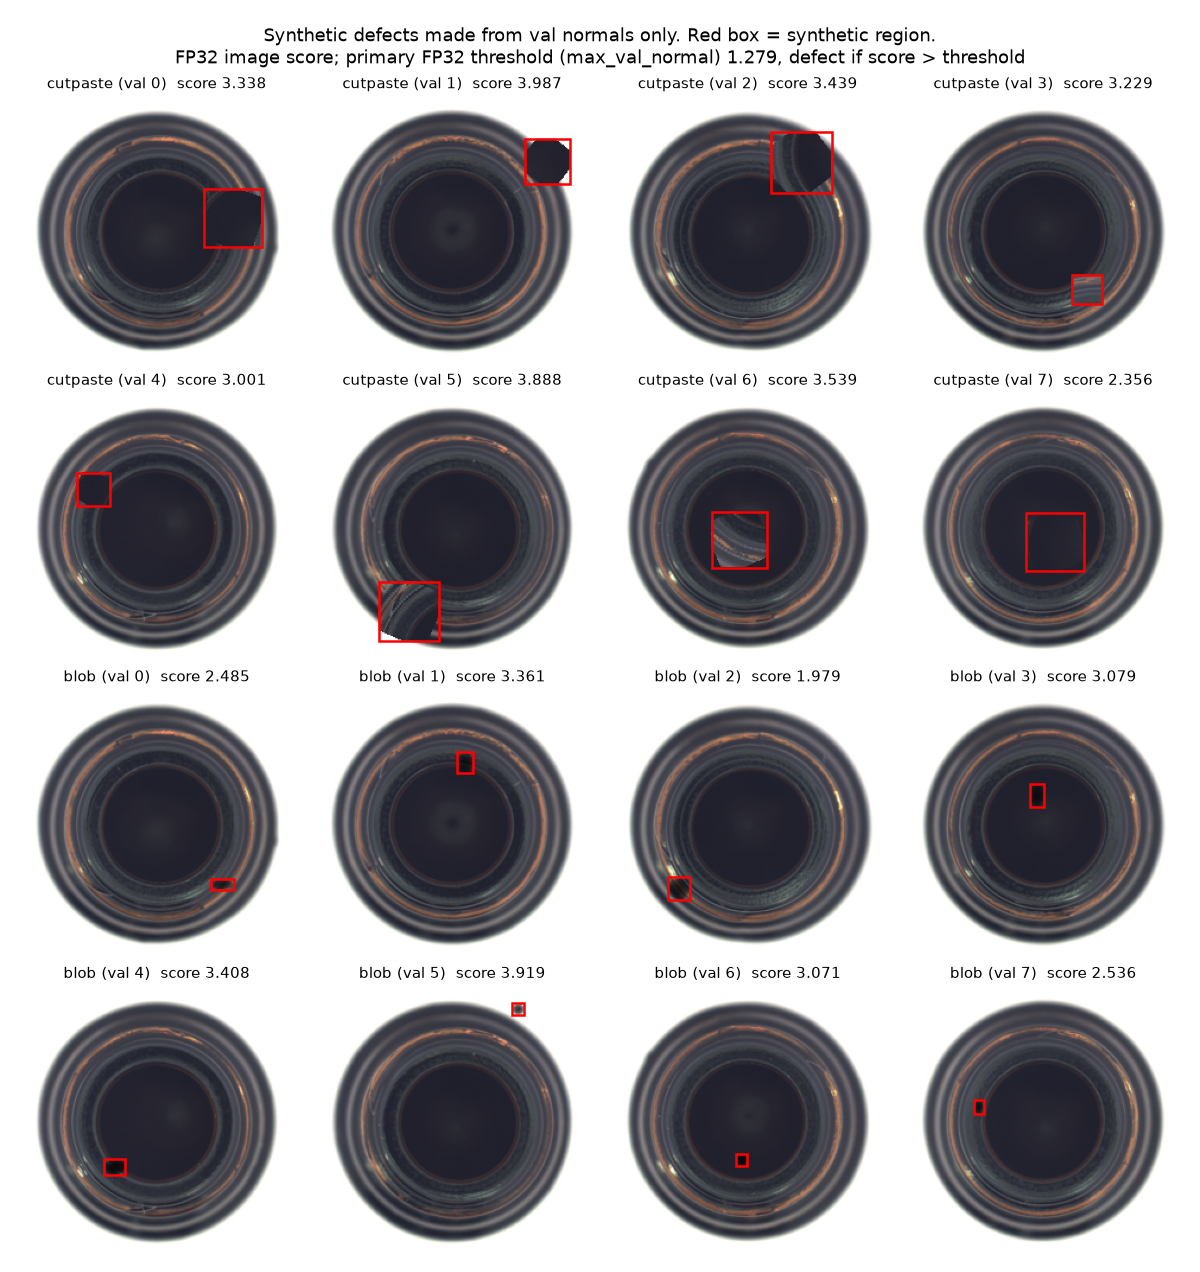

In [3]:
display(Markdown(architecture))
calib = json.loads((R / "calib.json").read_text(encoding="utf-8"))
thr = pd.DataFrame(calib["thresholds"]).T
thr["primary"] = calib["primary"]
display(thr)
display(Image(filename=str(R / "synth_grid.png"), width=700))

## 3. Clean results
Rule: defect if score > threshold. Intervals are exact Clopper-Pearson 95% intervals from the counts. The stratified bootstrap intervals in `clean.csv` collapse to [1, 1], because perfect separation makes every resample perfect, so they are not shown.

,variant,threshold,value,AUROC,AP,recall,FPR,precision,F1,recall by type
0,fp32,max_val_normal (primary),1.2792,1.0000,1.0000,"1.000 (63/63) [0.943, 1.000]","0.200 (4/20) [0.057, 0.437]",0.940 (63/67),0.969,"broken_large 20/20, broken_small 22/22, contamination 21/21"
1,fp32,f1_optimal (alternative),1.6292,1.0000,1.0000,"1.000 (63/63) [0.943, 1.000]","0.000 (0/20) [0.000, 0.168]",1.000 (63/63),1.000,"broken_large 20/20, broken_small 22/22, contamination 21/21"
2,int8,max_val_normal (primary),1.3339,1.0000,1.0000,"1.000 (63/63) [0.943, 1.000]","0.150 (3/20) [0.032, 0.379]",0.955 (63/66),0.977,"broken_large 20/20, broken_small 22/22, contamination 21/21"
3,int8,f1_optimal (alternative),1.6647,1.0000,1.0000,"1.000 (63/63) [0.943, 1.000]","0.000 (0/20) [0.000, 0.168]",1.000 (63/63),1.000,"broken_large 20/20, broken_small 22/22, contamination 21/21"


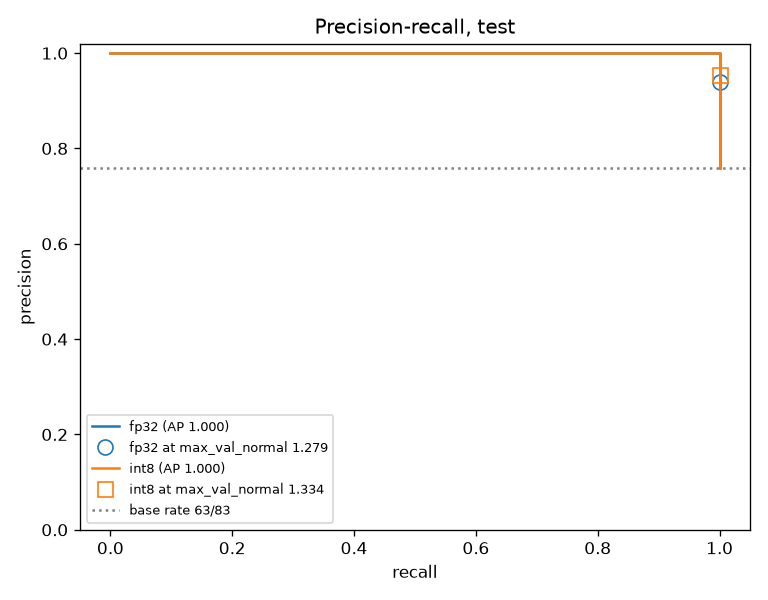

In [4]:
def cp(k, n):
    """Clopper-Pearson 95% interval for k successes out of n."""
    lo = 0.0 if k == 0 else beta.ppf(0.025, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(0.975, k + 1, n - k)
    return f"[{lo:.3f}, {hi:.3f}]"


clean = pd.read_csv(R / "clean.csv")
rows = []
for _, r in clean.iterrows():
    n_def, n_good = r.tp + r.fn, r.fp + r.tn
    rows.append({"variant": r.variant, "threshold": f"{r.threshold_name} ({r.role})", "value": f"{r.threshold:.4f}",
                 "AUROC": f"{r.auroc:.4f}", "AP": f"{r.ap:.4f}",
                 "recall": f"{r.recall:.3f} ({r.tp}/{n_def}) {cp(r.tp, n_def)}",
                 "FPR": f"{r.fpr:.3f} ({r.fp}/{n_good}) {cp(r.fp, n_good)}",
                 "precision": f"{r.precision:.3f} ({r.tp}/{r.tp + r.fp})", "F1": f"{r.f1:.3f}",
                 "recall by type": ", ".join(f"{c[7:]} {r[c]}" for c in clean.columns
                                             if c.startswith("recall_") and c[7:] not in ("ci_lo", "ci_hi"))})
display(pd.DataFrame(rows))
display(Image(filename=str(R / "pr_curve.png"), width=520))

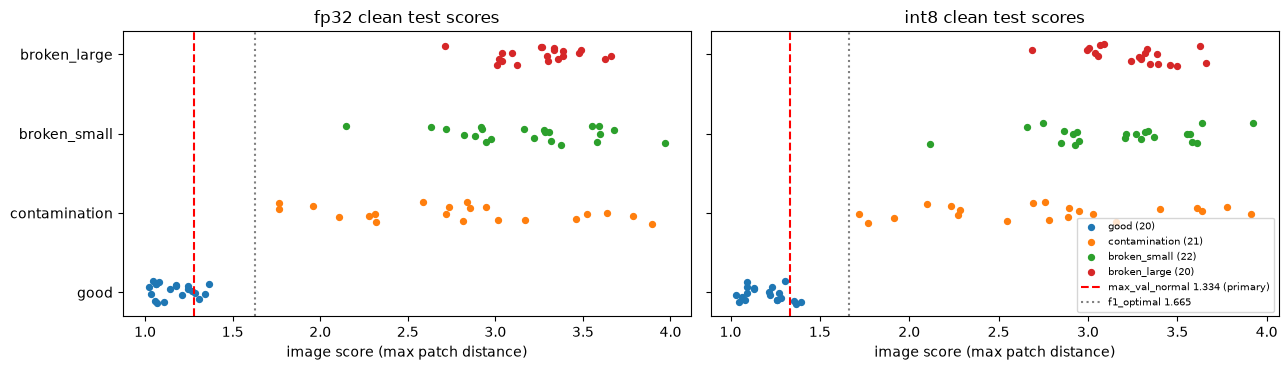

false alarms at the FP32 primary threshold:
                               path  fp32_onnx  int8_onnx
data/mvtec/bottle/test/good/001.png   1.344743   1.368720
data/mvtec/bottle/test/good/002.png   1.365187   1.393497
data/mvtec/bottle/test/good/009.png   1.287241   1.269746
data/mvtec/bottle/test/good/015.png   1.310380   1.354416


In [5]:
scores = pd.read_csv(R / "clean_scores.csv")
order = ["good", "contamination", "broken_small", "broken_large"]
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (v, col) in zip(axes, (("fp32", "fp32_onnx"), ("int8", "int8_onnx"))):
    for k, t in enumerate(order):
        s = scores.loc[scores.defect_type == t, col]
        ax.scatter(s, k + rng.uniform(-0.15, 0.15, len(s)), s=18, label=f"{t} ({len(s)})")
    t_prim, t_alt = calib["thresholds"][v]["max_val_normal"], calib["thresholds"][v]["f1_optimal"]
    ax.axvline(t_prim, color="red", ls="--", label=f"max_val_normal {t_prim:.3f} (primary)")
    ax.axvline(t_alt, color="gray", ls=":", label=f"f1_optimal {t_alt:.3f}")
    ax.set(title=f"{v} clean test scores", xlabel="image score (max patch distance)", yticks=range(4),
           yticklabels=order)
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()
good = scores[scores.label == 0]
print("false alarms at the FP32 primary threshold:")
print(good[good.fp32_onnx > calib["thresholds"]["fp32"]["max_val_normal"]][["path", "fp32_onnx", "int8_onnx"]]
      .to_string(index=False))

## 4. Leakage audit
From `docs/leakage_audit.md`.

In [6]:
display(Markdown((D / "leakage_audit.md").read_text(encoding="utf-8")))

# Leakage audit

Evidence that the test split stayed untouched until the single scored run. Values come from `git log`, the split CSVs, `results/` and a grep of `src/`. Commit times are local CDT (UTC-5) unless marked UTC.

| # | check | pass rule | value | result |
|---|---|---|---|---|
| 1 | Test manifest committed before the first model file | `splits/manifest.json` and `splits/test.csv` are committed before any model code or weights | Manifest and test.csv were committed in `73b70ee` at 2026-10-25 22:12:59. The first model files (`src/patchcore.py`, `results/quant.json`) were committed in `4916d88` at 2026-10-25 22:47:51, 35 minutes later. The committed manifest has never changed: `git log -- splits/manifest.json` lists only `73b70ee`. Before freeze, `python -m src.data --force` rewrote the working copy with LF line endings only; it rebuilt byte-identical CSVs with the same four CSV hashes. | PASS |
| 2 | Hash overlap across splits | 0 shared SHA-256 values between any two of fit, val and test; 0 duplicates within a split | fit x val 0, fit x test 0, val x test 0. Within-split duplicates: fit 0, val 0, calib 0, test 0. Shared paths: 0. | PASS |
| 3 | Parts or lots in two splits | 0 | 0. MVTec AD provides no part or lot IDs, and each image is a separate sample. The exact-hash check in row 2 is therefore the strongest check available. | PASS |
| 4 | Normalization source | Fixed constants, not computed from any split | ImageNet mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225) are hard-coded in `src/patchcore.py` (lines 23-24) and applied inside the model's forward. | PASS |
| 5 | Memory bank source | Fit split only | Both banks are built from `load_split("fit")` only: `src/patchcore.py:100` for FP32 and `src/quantize.py:115` for INT8. 188 images x 784 patches = 147,392 patches, reduced by coreset to 14,739 x 384 in both `bank_fp32.npy` and `bank_int8.npy`. | PASS |
| 6 | Threshold source and value | Val only, frozen before test | Set from 21 val normals plus 42 synthetic defects made from them (`src/calibrate.py:113`). FP32: max_val_normal 1.2792 (primary) and f1_optimal 1.6292. INT8: 1.3339 (primary) and 1.6647. Values committed in `4916d88` at 2026-10-25 22:47:51. The primary was switched to max_val_normal and committed in `942ee4e` at 2026-10-26 14:46:29. | PASS |
| 7 | INT8 calibration overlap with test | 0 | 0. calib is 50 images drawn from fit: calib not in fit 0, calib x val 0, calib x test 0. | PASS |
| 8 | Simulated defects made from | Val normals only | `src/calibrate.py:113` and the eval dry run (`src/eval.py:93`) call `load_split("val")` only. Every CutPaste donor and every blob base is a val normal. | PASS |
| 9 | Files that open test images | One call site, in `src/eval.py` | `grep -rn "allow_test=True" src/` finds one call: `src/eval.py:84`, inside `load_test()`. The other four matches are docstrings and an error message (`src/data.py:6, 86, 88`; `src/eval.py:81`). `src/data.py` reads test files only to check the 900x900 header and hash the bytes. `report.ipynb` reads only `results/` and `docs/`. Its first cell blocks every other path in the project except the installed libraries in `.venv/`, and the guard's own probe proves it fires. | PASS before the test run. Incident after the run: report.ipynb guard self-test opened one test file handle twice, no bytes read, no number affected, fixed (known issue 2). |
| 10 | Eval config committed before the run | Last commit of `eval_config.yaml` is earlier than the run start | `942ee4e` at 2026-10-26 14:46:29 CDT (19:46:29 UTC). The test run started at 19:46:38 UTC. `results/freeze.json`, in the same commit, hashes the config, and eval.py verified all 11 frozen hashes before loading test. | PASS |
| 11 | Evaluation runs | Exactly 1 on test; dry runs on val only | 1 test run: start 19:46:38 UTC, end 19:57:24 UTC, eval.py sha256 `80dc9f3c...` (run log below). 2 dry runs, both on val, at 04:27 and 19:30 UTC (`results/dryrun/run_log.txt`); neither called the test loader. eval.py changed after the second dry run in three places, all in the freeze and test-integrity checks that dry runs skip. That is why the test run's eval.py hash differs from the dry-run hashes. | PASS |

## Known issue
- At the end of the test run, eval.py printed "wrote 39 files". That count is wrong, because the listing includes every file already in `results/`, such as the banks, the ONNX files and `dryrun/`. The run actually wrote 17 files: 10 in `results/` (clean.csv, clean_scores.csv, attack.csv, attack_scores.csv, sanity.txt, pr_curve.png, degradation_curve.png, tradeoff.csv, tradeoff.md, .scored) and 7 in `results/misses/`. `results/eval_log.txt` came from the shell redirect, and this file got its run-log lines. The count is not fixed, because eval.py is frozen.
- While `report.ipynb` was being built on 2026-10-26, after the test run, the first two executions opened a file handle on `data/mvtec/bottle/test/good/000.png` without reading it. The guard cell's self-test tried to open that file to prove the guard worked. IPython puts its own `open()` into the notebook namespace, and that wrapper went around the guard, so the open succeeded. No bytes were read, nothing was computed or displayed, and the handle was dropped. The saved notebook now sends the namespace `open` through the guard too. Its self-test probes a path that does not exist (`data/guard_probe_does_not_exist.png`), so it cannot open a real file even if the guard breaks, and it prints "guard OK".
- On 2026-10-26, before the first push to GitHub, the git history was rewritten for two reasons: to replace the author email with the GitHub noreply address, and to remove the governance memo, which is submitted separately and kept out of git. Every file in every commit is unchanged except that the memo is gone, and every author and commit date is unchanged, so the times in this table still hold. The commit hashes changed, and this table cites the new ones. Old to new: 4c16cbb -> 2d0286b, 07078dd -> 73b70ee, bf8ecba -> 7358f3e, f5ab5be -> 4916d88, ee09339 -> 942ee4e, 7ab394e -> 2ac4d0d (test run), 90e5248 -> e0f5e52. The commit `memo: restore table header` changed only the memo, so it was empty after the rewrite and was dropped.

## eval.py run log

- 2026-10-26 19:46:38 UTC eval.py start (test), sha256 80dc9f3cd256c51966c0b8a47b13118c9843c419844181a33c7c5920d53422f2
- 2026-10-26 19:57:24 UTC eval.py end (test), all outputs written


## 5. Attacks on FP32
White-box, L-infinity, two-sided: defects are pushed down (escape) and good parts up (false alarm). Recall and FPR are at the primary threshold. Eps is also shown in gray levels out of 255.

,attack,eps,gray levels,two-sided AUROC,escape AUROC,false-alarm AUROC,recall,FPR,new escapes,new false alarms
0,FGSM,0.000,0.0,1.0000,1.000,1.0000,1.000 (63/63),0.200 (4/20),0,0
1,FGSM,0.005,1.3,0.9500,1.000,0.9857,1.000 (63/63),1.000 (20/20),0,16
2,FGSM,0.010,2.6,0.8905,1.000,0.9389,1.000 (63/63),1.000 (20/20),0,16
3,FGSM,0.015,3.8,0.8690,1.000,0.9135,1.000 (63/63),1.000 (20/20),0,16
4,FGSM,0.020,5.1,0.8659,1.000,0.8857,1.000 (63/63),1.000 (20/20),0,16
5,FGSM,0.030,7.6,0.8206,1.000,0.8206,1.000 (63/63),1.000 (20/20),0,16
6,FGSM,0.050,12.8,0.7095,1.000,0.6024,1.000 (63/63),1.000 (20/20),0,16
7,"PGD 10 steps, alpha 0.25 x eps, 1 restart, random start",0.005,1.3,0.1905,0.996,0.4786,1.000 (63/63),1.000 (20/20),0,16
8,"PGD 10 steps, alpha 0.25 x eps, 1 restart, random start",0.010,2.6,0.0000,1.000,0.0111,1.000 (63/63),1.000 (20/20),0,16
9,"PGD 10 steps, alpha 0.25 x eps, 1 restart, random start",0.020,5.1,0.0000,1.000,0.0000,1.000 (63/63),1.000 (20/20),0,16


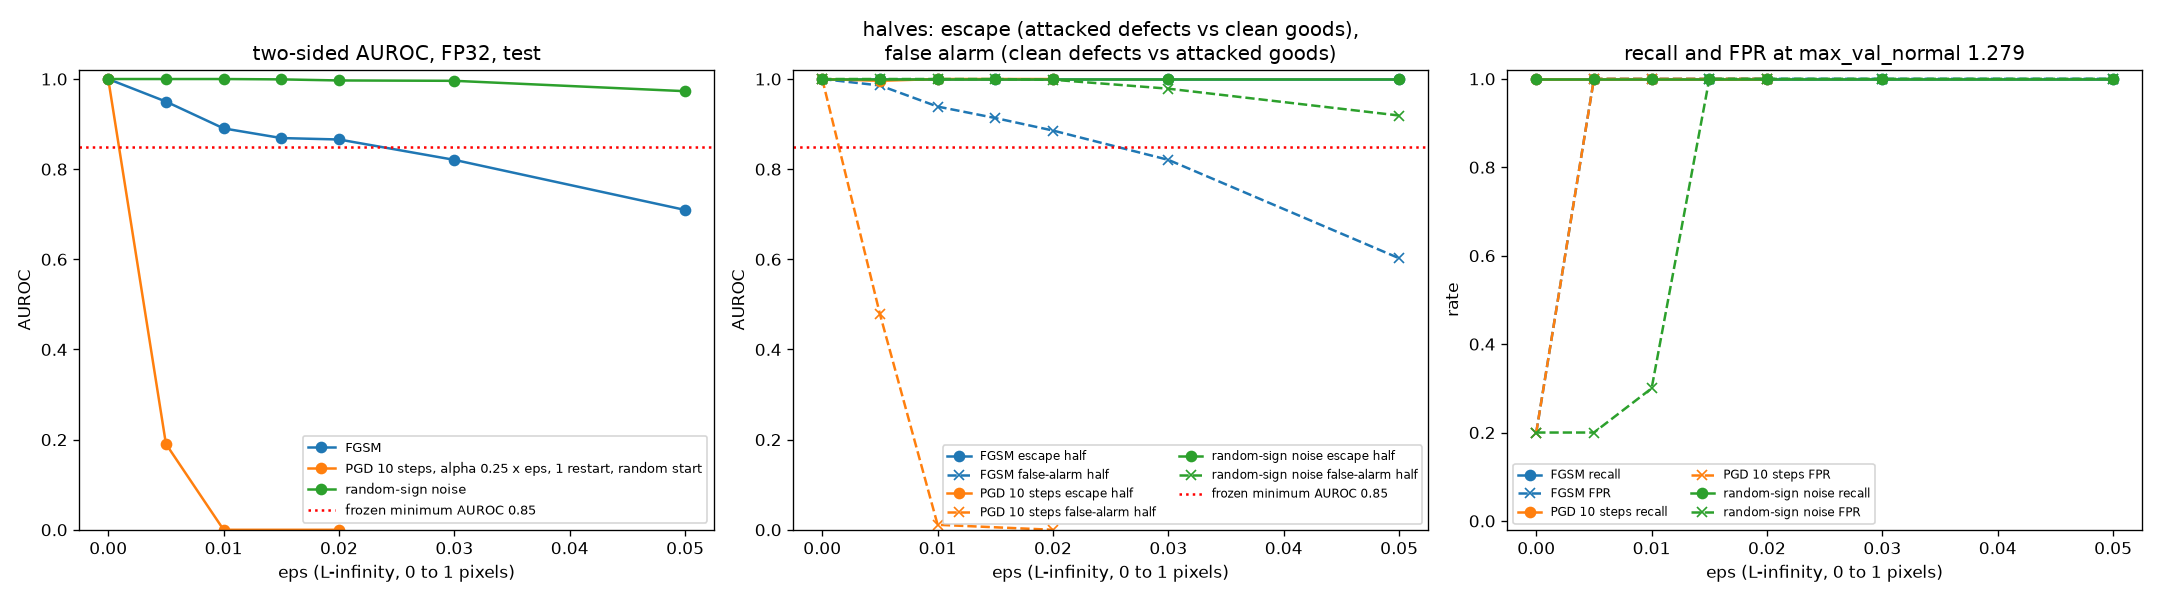

In [7]:
att = pd.read_csv(R / "attack.csv")
display(pd.DataFrame({
    "attack": att.label, "eps": att.eps, "gray levels": (att.eps * 255).round(1),
    "two-sided AUROC": att.auroc.round(4), "escape AUROC": att.auroc_escape.round(4),
    "false-alarm AUROC": att.auroc_false_alarm.round(4),
    "recall": [f"{r.recall:.3f} ({r.tp}/{r.n_defect})" for r in att.itertuples()],
    "FPR": [f"{r.fpr:.3f} ({r.fp_false_alarms}/{r.n_good})" for r in att.itertuples()],
    "new escapes": att.new_escapes, "new false alarms": att.new_false_alarms}))
display(Image(filename=str(R / "degradation_curve.png")))

**Post hoc** (computed from `attack_scores.csv` after the run; no frozen setting changed). For each attack and eps: the mean drop in defect scores, the lowest attacked defect score with its margin to the primary threshold, and the escapes there would have been at the alternative f1_optimal threshold.

In [8]:
s = pd.read_csv(R / "attack_scores.csv")
t_prim, t_alt = calib["thresholds"]["fp32"]["max_val_normal"], calib["thresholds"]["fp32"]["f1_optimal"]
d = s[s.label == 1]
g = d.groupby(["attack", "eps"])
display(pd.DataFrame({
    "mean defect score drop": g.apply(lambda x: (x.clean_score - x.adv_score).mean(), include_groups=False).round(3),
    "lowest attacked defect": g.adv_score.min().round(3),
    "margin to primary": (g.adv_score.min() - t_prim).round(3),
    f"escapes at f1_optimal {t_alt:.4f} (of 63)": g.apply(lambda x: int((x.adv_score <= t_alt).sum()),
                                                        include_groups=False)}))

mean defect score drop  lowest attacked defect  margin to primary  escapes at f1_optimal 1.6292 (of 63)
attack      eps                                                                                                           
fgsm        0.000                   0.000                   1.765              0.486                                     0
            0.005                   0.392                   1.478              0.198                                     2
            0.010                   0.382                   1.841              0.562                                     0
            0.015                   0.322                   2.001              0.722                                     0
            0.020                   0.253                   2.151              0.872                                     0
            0.030                   0.127                   2.432              1.153                                     0
            0.050                  -0.084                   2.785              1.506                                     0
pgd         0.005                   0.698                   1.310              0.031                                     4
            0.010                   0.836                   1.391              0.112                                     4
            0.020                   0.786                   1.702              0.423                                     0
random_sign 0.000                   0.000                   1.765              0.486                                     0
            0.005                   0.009                   1.704              0.425                                     0
            0.010                   0.020                   1.645              0.365                                     0
            0.015                   0.032                   1.605              0.326                                     1
            0.020                   0.036                   1.628              0.349                                     1
            0.030                   0.022                   1.912              0.633                                     0
            0.050                  -0.030                   2.192              0.912                                     0

## 6. INT8 tradeoff
Latency was measured on the declared edge target through ONNX Runtime (`results/bench.json`). The INT8 checks are from `results/quant.json`.

In [9]:
display(Markdown((R / "tradeoff.md").read_text(encoding="utf-8")))
quant = json.loads((R / "quant.json").read_text(encoding="utf-8"))
bench = json.loads((R / "bench.json").read_text(encoding="utf-8"))
v = quant["verification"]
print(f"calibration: {quant['calibration']}; method picked on val: {quant['picked']}")
print(f"QuantizeLinear {v['QuantizeLinear']}, DequantizeLinear {v['DequantizeLinear']}, "
      f"Conv with int8 weights {v['conv_int8_weights']}/{v['conv_total']}, runtime QLinearConv "
      f"{v['runtime_QLinearConv']}, float Conv {v['runtime_float_conv']}")
print(f"fp32.onnx vs PyTorch max abs diff {quant['parity_fp32_onnx_vs_pytorch_max_abs_diff']:.2e}; "
      f"INT8 vs FP32 per-patch cosine mean {quant['methods'][quant['picked']]['cos_mean']:.4f}")
print(f"bench: {bench['cpu']}, {bench['runtime']}, {bench['schedule']}, notes: {bench['notes']}")
display(pd.DataFrame({k: {f"{part} {q}": val[part][q] for part in ("extractor", "nn", "total")
                          for q in ("p50", "p95", "p99")} for k, val in bench["variants"].items()}))

# Accuracy-latency-size tradeoff (test)

Accuracy at the primary threshold (max_val_normal, frozen on val). Latency = ONNX Runtime extractor + nearest-neighbor search, batch 1, 4 threads, on Intel(R) Core(TM) Ultra 7 155U (results/bench.json). Size = ONNX file + bank file, MB = 2^20 bytes.

| variant | AUROC | AP | F1 | recall | p50 ms | p95 ms | size MB |
|---|---|---|---|---|---|---|---|
| fp32 | 1.0000 | 1.0000 | 0.969 | 1.000 (63/63) | 95.24 | 114.00 | 32.21 |
| int8 | 1.0000 | 1.0000 | 0.977 | 1.000 (63/63) | 84.56 | 98.14 | 24.31 |


calibration: splits/calib.csv, 50 images; method picked on val: percentile
QuantizeLinear 27, DequantizeLinear 57, Conv with int8 weights 15/15, runtime QLinearConv 15, float Conv 0
fp32.onnx vs PyTorch max abs diff 5.36e-06; INT8 vs FP32 per-patch cosine mean 0.9988
bench: Intel(R) Core(TM) Ultra 7 155U, ONNX Runtime 1.31.0 CPUExecutionProvider, graph optimization ORT_ENABLE_ALL, interleaved, order alternated, notes: plugged in, Zoom/Teams/browsers closed, VS Code with Claude Code running


,fp32,int8
extractor p50,14.446,6.740
extractor p95,18.072,8.070
extractor p99,18.992,8.632
nn p50,79.875,77.792
nn p95,98.213,91.427
nn p99,102.701,99.464
total p50,95.239,84.557
total p95,113.998,98.143
total p99,119.051,106.807


## 7. Sanity checks
From `results/sanity.txt`. Check 3 is a FAIL; the explanation is in `docs/failure_report.md` section 4.5.

In [10]:
print((R / "sanity.txt").read_text(encoding="utf-8"))

Sanity checks, test, attacks on FP32 torch
damage (checks 3 and 5) = mean over images of the score shift toward the attacker's goal (+ for good images pushed up, + for defects pushed down)
check 4 = drop in two-sided AUROC from clean (1.0000); its cutoff was revised after the val dry run, before freeze (docs/failure_report.md)

1 PASS  eps 0 reproduces clean scores exactly: {'fgsm': True, 'random_sign': True}
2 PASS  max |x_adv - x| <= eps + 1e-6 for every attack x eps (largest excess: fgsm eps 0.005, +2.51e-08); pixels in [0.0598, 1.0000]
3 FAIL  damage grows with eps: FGSM [0: 0.0000, 0.005: 0.4333, 0.01: 0.5062, 0.015: 0.5071, 0.02: 0.4879, 0.03: 0.4521, 0.05: 0.3812]; PGD [0: 0.0000, 0.005: 1.0287, 0.01: 1.6043, 0.02: 2.1223]
4 PASS  random-sign AUROC drop <= 0.25 x FGSM AUROC drop, or <= 0.01: eps 0.005 drop 0.0000 vs 0.0500 (score shift, info only: 0.0083 vs 0.4333), eps 0.01 drop 0.0000 vs 0.1095 (score shift, info only: 0.0317 vs 0.5062), eps 0.015 drop 0.0008 vs 0.1310 (score 

## 8. Misses
Every clean false alarm at the FP32 primary threshold (there were no clean misses), and the 3 lowest-scoring defects under PGD eps 0.01.

**fp_good_001.png**

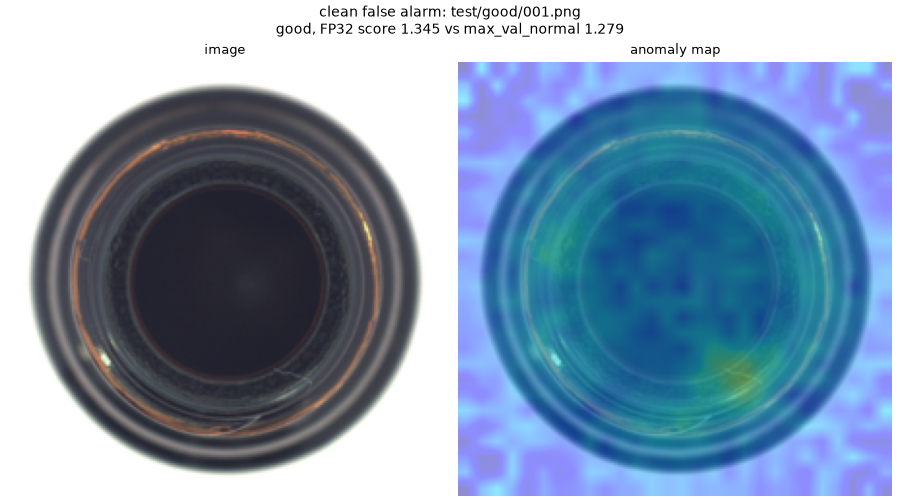

**fp_good_002.png**

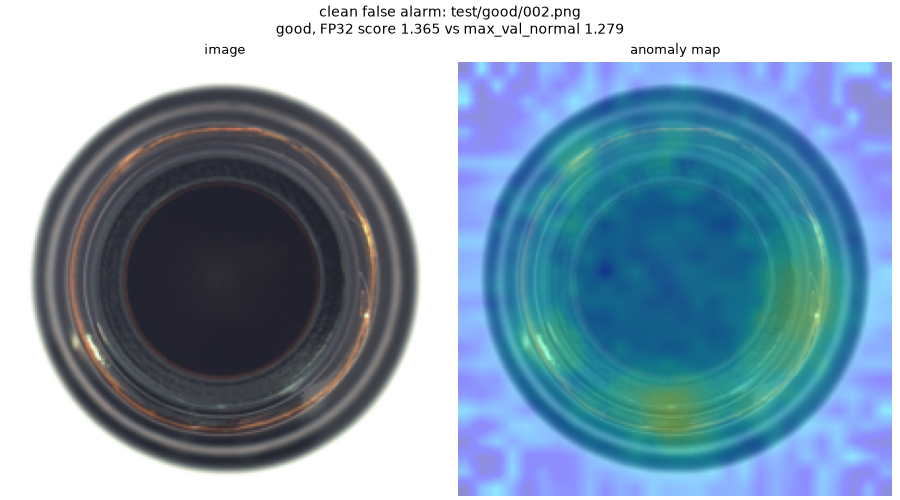

**fp_good_009.png**

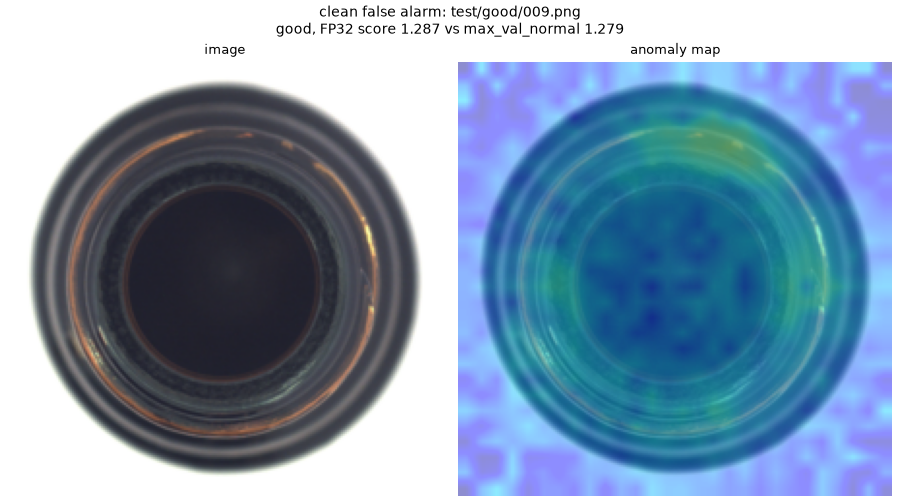

**fp_good_015.png**

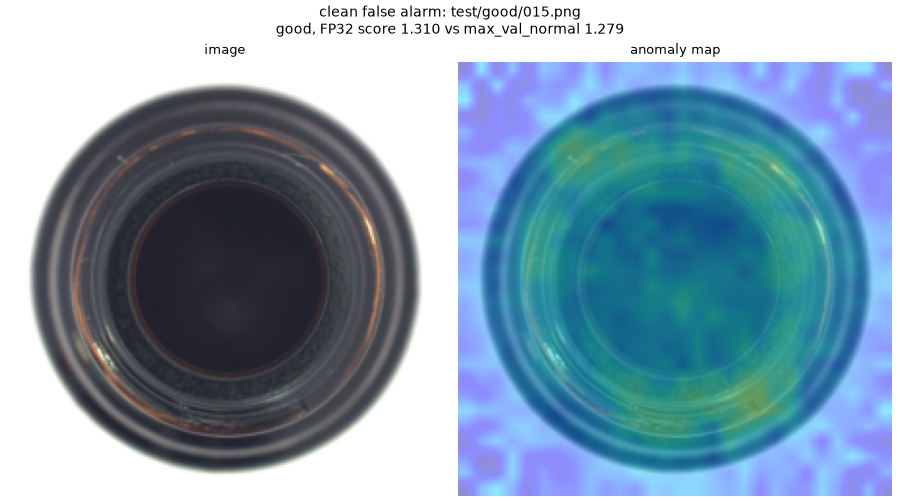

**pgd001_low1_contamination_003.png**

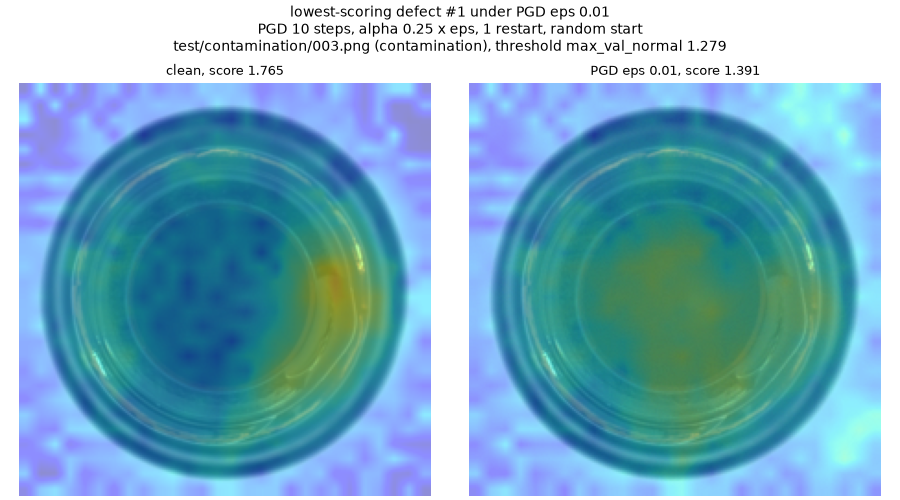

**pgd001_low2_contamination_019.png**

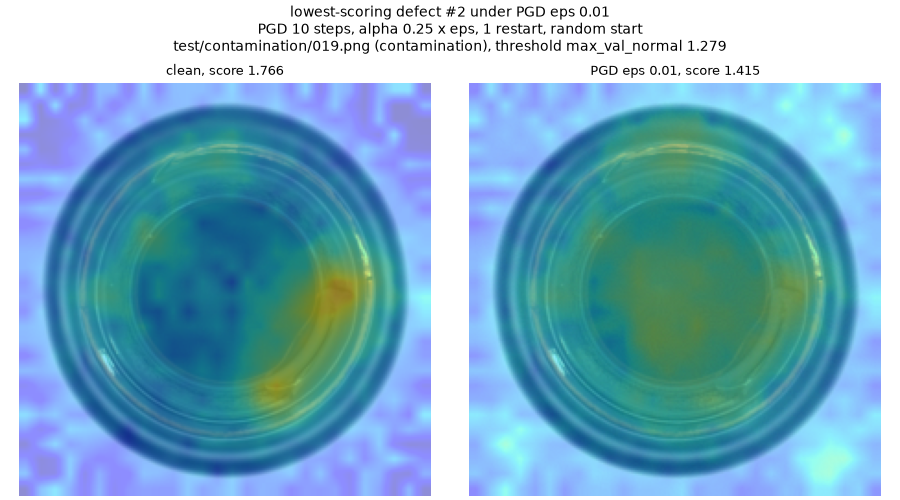

**pgd001_low3_contamination_004.png**

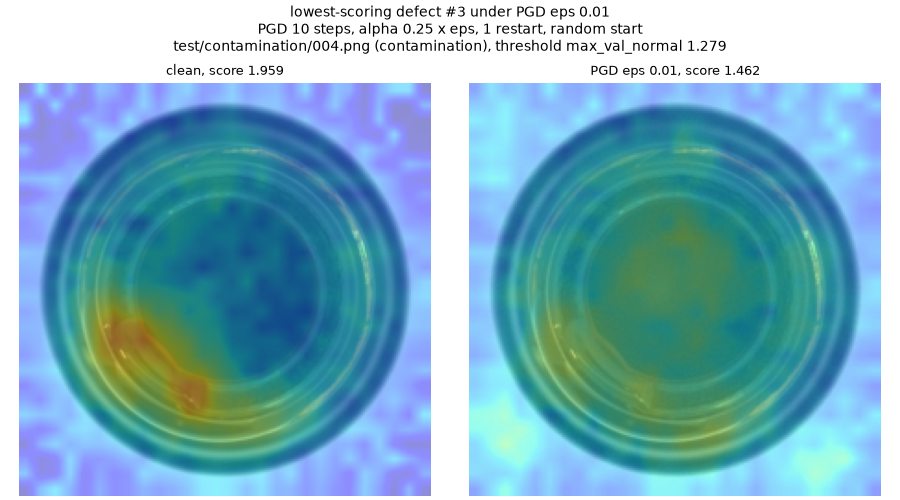

In [11]:
for p in sorted((R / "misses").glob("*.png")):
    display(Markdown(f"**{p.name}**"))
    display(Image(filename=str(p), width=620))